# Check imcombine statistics

Generate synthetic 1024 × 1024 SPARC4-like bias exposures and compare **median, mean, and one-pass sigma-clipped combinations** using `uint16` and `float32` storage. The settings below control the number of frames, Gaussian bias/read noise, and signed transient spikes. Numerical camera settings are illustrative, not measured instrument calibration.

Both working dtypes receive exactly the same **quantized uint16 inputs**. A float32 result therefore preserves fractional combination values, but cannot restore fractions discarded while generating input frames. Runtime is offline. Run from the `astropop-studies` directory, using the desired Astropop installation in the Jupyter kernel; its path/version are printed below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.stats import sigma_clip, mad_std
from astropy.table import Table

# use kernel installed astropop, not system-wide
from astropop.config import AstropopConfig as conf
from astropop.framedata import FrameData
from astropop.image.imcombine import imcombine

# All image levels, noise and spike amplitudes are in ADU.
seed = 20261019
shape = (1024, 1024)
n_frames = 300
bias_level = 1000.0
read_noise = 30
sigma_threshold = 3.0
positive_spike_rate = 0.002           # probability per pixel per exposure
positive_spike_range = (100.0, 2000.0)
negative_spike_rate = 0.0005
negative_spike_range = (100.0, 500.0)
memory_limit = 64 * 2**20             # chunk-workspace budget

import inspect
import platform
import sys
from pathlib import Path
from IPython.display import display
import astropop
from library.imcombine_benchmark import make_bias_frames, measure_combination

conf.FRAMEDATA_DISABLE_FLAGS = True
conf.FRAMEDATA_DISABLE_UNCERTAINTY = True

simulation = dict(seed=seed, shape=shape, n_frames=n_frames, bias_level=bias_level,
                  read_noise=read_noise, positive_spike_rate=positive_spike_rate,
                  positive_spike_range=positive_spike_range,
                  negative_spike_rate=negative_spike_rate,
                  negative_spike_range=negative_spike_range)

In [2]:
# Seeded generation shared with the isolated benchmark workers.
# Only one input sequence is held; every combination reads these same frames.
frame_list = make_bias_frames(**simulation)
print(f'Generated {len(frame_list)} uint16 FrameData images with ADU units.')
print(f'Input data: {sum(f.data.nbytes for f in frame_list)/2**20:.1f} MiB')
print('Single-frame means:', [round(float(f.data.mean()), 2) for f in frame_list[:5]])


Generated 300 uint16 FrameData images with ADU units.
Input data: 600.0 MiB
Single-frame means: [1001.45, 1001.52, 1001.41, 1001.4, 1001.47]


## Median comparison

Compare dtype choices using the same fixed image scale and discrete-value histograms. For clean Gaussian noise, the large-sample median standard error is approximately `sqrt(pi/2) * read_noise / sqrt(n_frames)`; spikes and input quantization change that reference slightly. The noiseless analog level is `bias_level`. Quantization of positive noisy samples shifts the clean input mean and symmetry center approximately to `bias_level - 0.5` ADU.

In [3]:
median_uint16 = imcombine(frame_list, method='median', memory_limit=memory_limit, dtype=np.uint16)
median_float32 = imcombine(frame_list, method='median', memory_limit=memory_limit, dtype=np.float32)

2026-10-19 15:28:23,238 astropop - INFO - Combining 300 images with median method.  [imcombine]
2026-10-19 15:28:32,005 astropop - INFO - Combining 300 images with median method.  [imcombine]


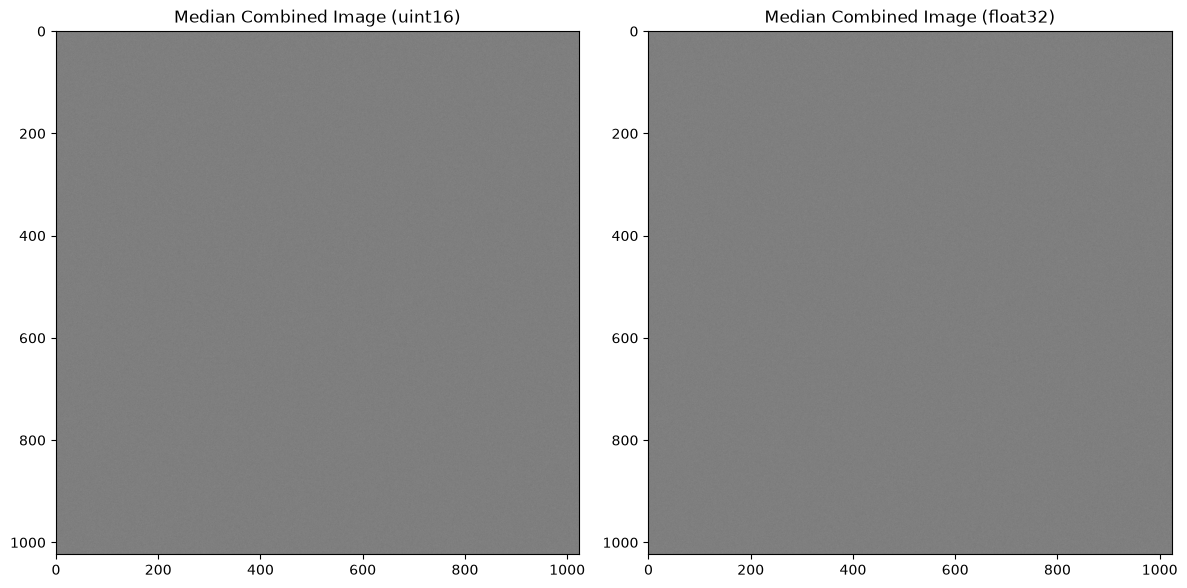

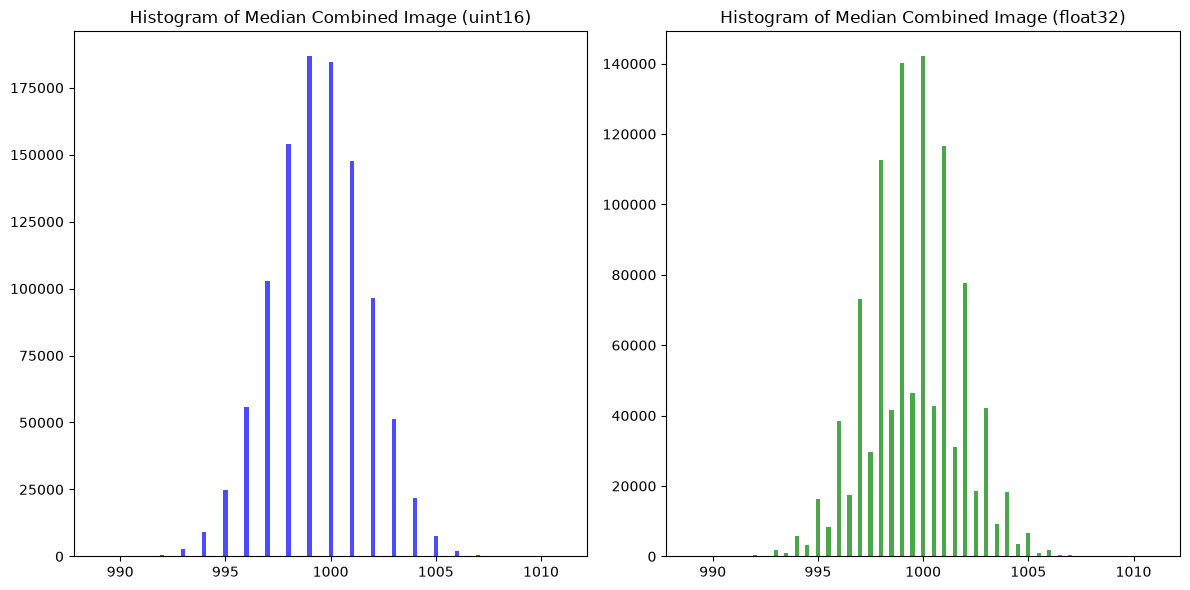

In [4]:
f, ax = plt.subplots(1, 2, figsize=(12, 6))
# Display the median combined image in uint16
im1 = ax[0].imshow(median_uint16.data, cmap='gray', vmin=bias_level - 3 * read_noise, vmax=bias_level + 3 * read_noise)
ax[0].set_title('Median Combined Image (uint16)')
# Display the median combined image in float32
im2 = ax[1].imshow(median_float32.data, cmap='gray', vmin=bias_level - 3 * read_noise, vmax=bias_level + 3 * read_noise)
ax[1].set_title('Median Combined Image (float32)')
f.tight_layout()

unit16_values, uint16_counts = np.unique(median_uint16.data.ravel(), return_counts=True)
float32_values, float32_counts = np.unique(median_float32.data.ravel(), return_counts=True)

f, ax = plt.subplots(1, 2, figsize=(12, 6))
# Display the histogram of the median combined image in uint16
ax[0].bar(unit16_values, uint16_counts, width=0.2, color='blue', alpha=0.7)
ax[0].set_title('Histogram of Median Combined Image (uint16)')
# Display the histogram of the median combined image in float32
ax[1].bar(float32_values, float32_counts, width=0.2, color='green', alpha=0.7)
ax[1].set_title('Histogram of Median Combined Image (float32)')
f.tight_layout()

In [5]:
print(f"Median combined image (uint16) mean: {np.mean(median_uint16.data):.2f}, std: {np.std(median_uint16.data):.2f}")
print(f"Median combined image (float32) mean: {np.mean(median_float32.data):.2f}, std: {np.std(median_float32.data):.2f}")

Median combined image (uint16) mean: 999.44, std: 2.19
Median combined image (float32) mean: 999.56, std: 2.18


### Why are half-ADU median values less frequent?

For an **even** number of input frames, the median averages the two central ordered samples. With integer inputs, equal central samples produce an integer; adjacent central samples produce a half-integer. Central samples often tie because many of the 300 samples land in the same ADU bin. Different central values can also average to an integer when their sum is even. Half-integer outcomes are therefore not equally likely to integer outcomes.

Float32 preserves these half-ADU results. Uint16 truncates them toward zero when storing the output, creating an additional downward shift for positive data. For an odd frame count, there is one central sample and no half-integer median from these integer inputs. The selected-pixel reference below measures ties and half-integer frequency directly.

## Mean comparison without rejection

The mean uses all samples, so positive spikes can bias it upward and broaden its pixel distribution. For the clean Gaussian component alone the standard error is `read_noise / sqrt(n_frames)`. The signed spike mixture has a different mean and variance, calculated below.

With current Astropop, NumPy promotes the mean accumulator before the final dtype conversion. For example, 150 samples of 1000 ADU must average to 1000, rather than wrapping the sum in uint16. Integer output still discards fractional ADU at the end.

In [6]:
mean_uint16 = imcombine(frame_list, method='mean', memory_limit=memory_limit, dtype=np.uint16)
mean_float32 = imcombine(frame_list, method='mean', memory_limit=memory_limit, dtype=np.float32)

2026-10-19 15:28:38,095 astropop - INFO - Combining 300 images with mean method.  [imcombine]
2026-10-19 15:28:39,965 astropop - INFO - Combining 300 images with mean method.  [imcombine]


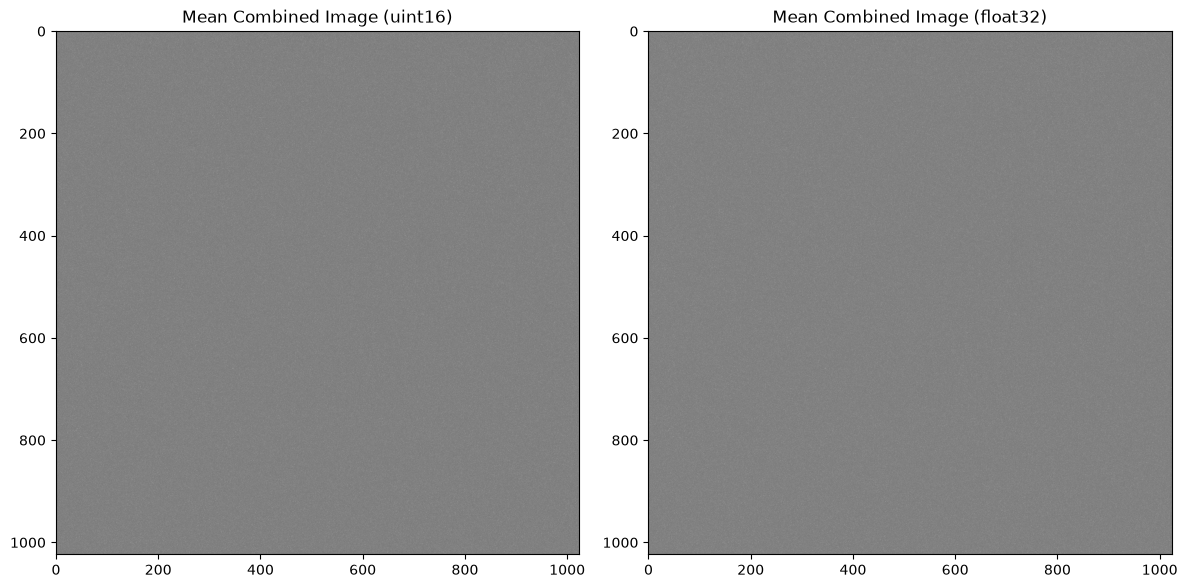

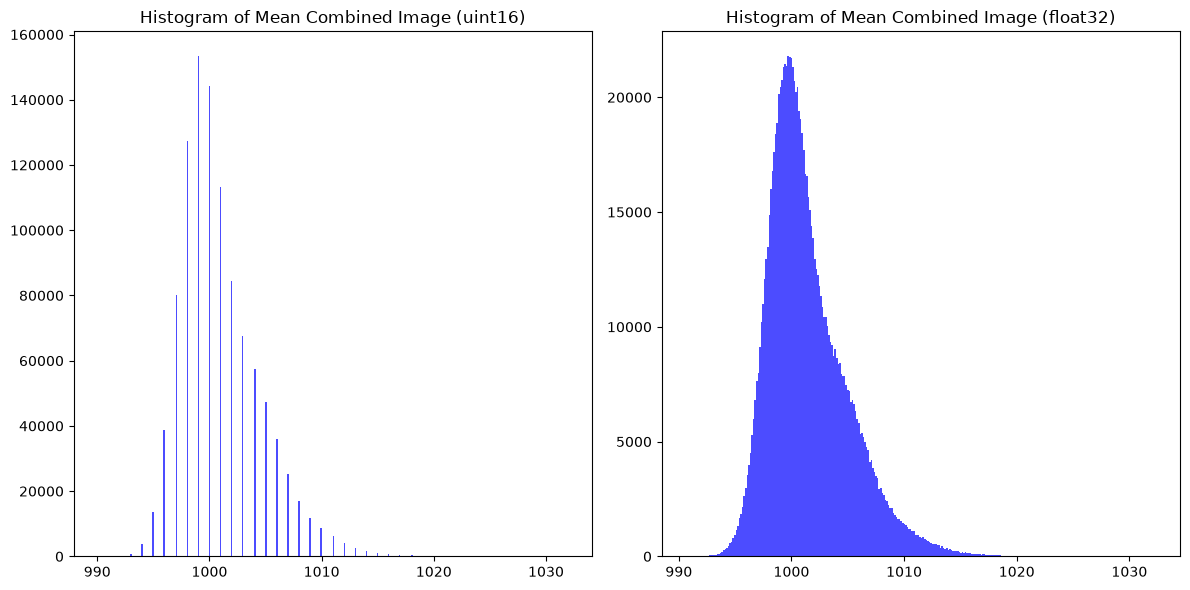

In [7]:
f, ax = plt.subplots(1, 2, figsize=(12, 6))
im1 = ax[0].imshow(mean_uint16.data, cmap='gray', vmin=bias_level - 3 * read_noise, vmax=bias_level + 3 * read_noise)
ax[0].set_title('Mean Combined Image (uint16)')
im2 = ax[1].imshow(mean_float32.data, cmap='gray', vmin=bias_level - 3 * read_noise, vmax=bias_level + 3 * read_noise)
ax[1].set_title('Mean Combined Image (float32)')
f.tight_layout()

f, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].hist(mean_uint16.data.ravel(), bins=300, color='blue', alpha=0.7)
ax[0].set_title('Histogram of Mean Combined Image (uint16)')
ax[1].hist(mean_float32.data.ravel(), bins=300, color='blue', alpha=0.7)
ax[1].set_title('Histogram of Mean Combined Image (float32)')
f.tight_layout()

So, as expected, the float32 is not discretized and the uint16 is. Also, the high value tail of the spikes is visible here.

In [8]:
print(f"Mean combined image (uint16) mean: {np.mean(mean_uint16.data):.2f}, std: {np.std(mean_uint16.data):.2f}")
print(f"Mean combined image (float32) mean: {np.mean(mean_float32.data):.2f}, std: {np.std(mean_float32.data):.2f}")

Mean combined image (uint16) mean: 1000.95, std: 3.55
Mean combined image (float32) mean: 1001.45, std: 3.54


## Sigma clipping: compare methods and dtypes

Use the same input sequence and a median rejection center in all clipped runs:

- **Mean + σ (std)**: `method='mean'`, `sigma_cen_func='median'`, `sigma_dev_func='std'`.
- **Mean + σ (MAD)**: `method='mean'`, `sigma_cen_func='median'`, `sigma_dev_func='mad_std'`.
- **Median + σ (MAD)**: `method='median'` with that same robust rejection.

`sigma_threshold` applies symmetrically. All cases use **one clipping pass**, matching Astropop's implementation; the comparison below uses Astropy with `maxiters=1`, not clipping to convergence. Standard deviation can be inflated by spikes, whereas Gaussian-scaled MAD resists them. Rejection is performed along the frame axis, independently at every detector pixel.

In [9]:
strategies = {
    'Mean': dict(method='mean'),
    'Median': dict(method='median'),
    'Mean + σ (std)': dict(method='mean', sigma_clip=sigma_threshold,
                          sigma_cen_func='median', sigma_dev_func='std'),
    'Mean + σ (MAD)': dict(method='mean', sigma_clip=sigma_threshold,
                          sigma_cen_func='median', sigma_dev_func='mad_std'),
    'Median + σ (MAD)': dict(method='median', sigma_clip=sigma_threshold,
                            sigma_cen_func='median', sigma_dev_func='mad_std'),
}
results = {'Mean': {'uint16': mean_uint16, 'float32': mean_float32},
           'Median': {'uint16': median_uint16, 'float32': median_float32}}
for name, options in strategies.items():
    if name in results:
        continue
    results[name] = {}
    for dtype_name in ('uint16', 'float32'):
        print(f'Combining {name}, dtype={dtype_name}', flush=True)
        results[name][dtype_name] = imcombine(
            frame_list, memory_limit=memory_limit, dtype=dtype_name, **options)


Combining Mean + σ (std), dtype=uint16


2026-10-19 15:28:44,001 astropop - INFO - Combining 300 images with mean method.  [imcombine]


Combining Mean + σ (std), dtype=float32


2026-10-19 15:28:58,293 astropop - INFO - Combining 300 images with mean method.  [imcombine]


Combining Mean + σ (MAD), dtype=uint16


...

2026-10-19 15:29:30,112 astropop - INFO - Combining 300 images with mean method.  [imcombine]


Combining Median + σ (MAD), dtype=uint16


2026-10-19 15:29:45,646 astropop - INFO - Combining 300 images with median method.  [imcombine]


Combining Median + σ (MAD), dtype=float32


2026-10-19 15:30:11,416 astropop - INFO - Combining 300 images with median method.  [imcombine]


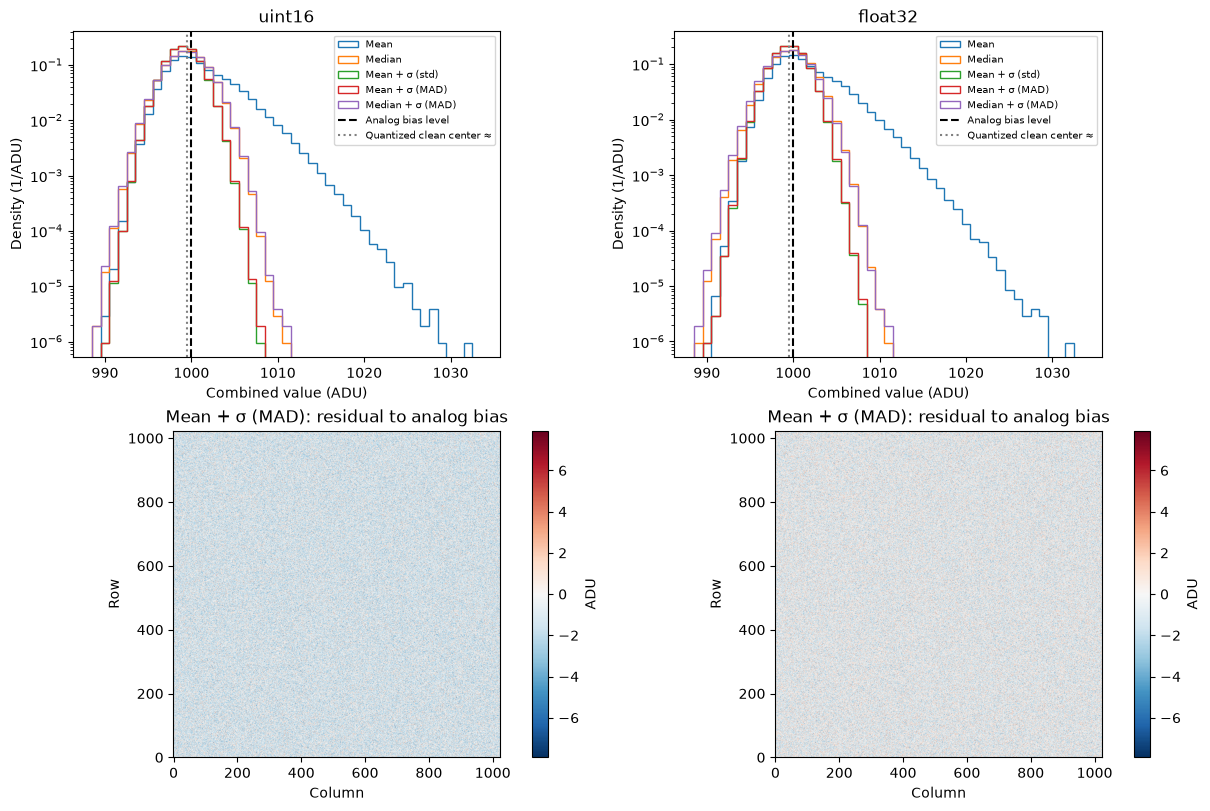

In [10]:
# One histogram and residual map per dtype: robust clipping should recover
# the narrow core without hiding the un-clipped mean's tails.
colors = dict(zip(strategies, plt.get_cmap('tab10').colors))
low = min(float(image.data.min()) for group in results.values() for image in group.values())
high = max(float(image.data.max()) for group in results.values() for image in group.values())
bins = np.arange(np.floor(low)-0.5, np.ceil(high)+1.5, 1.0)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for col, dtype_name in enumerate(('uint16', 'float32')):
    for name, group in results.items():
        axes[0, col].hist(group[dtype_name].data.ravel(), bins=bins,
                          density=True, histtype='step', color=colors[name], label=name)
    axes[0, col].axvline(bias_level, color='black', ls='--', label='Analog bias level')
    axes[0, col].axvline(bias_level-0.5, color='0.5', ls=':', label='Quantized clean center ≈')
    axes[0, col].set(title=dtype_name, xlabel='Combined value (ADU)',
                     ylabel='Density (1/ADU)', yscale='log')
    axes[0, col].legend(fontsize=7)
    residual = results['Mean + σ (MAD)'][dtype_name].data.astype(float)-bias_level
    limit = 4*read_noise/np.sqrt(n_frames)+1
    image = axes[1, col].imshow(residual, origin='lower', cmap='RdBu_r',
                                vmin=-limit, vmax=limit)
    axes[1, col].set(title='Mean + σ (MAD): residual to analog bias',
                     xlabel='Column', ylabel='Row')
    fig.colorbar(image, ax=axes[1, col], label='ADU')
plt.show()


## Independent reference and summary statistics

A seeded sample of detector pixels supplies a small `(n_frames, n_pixels)` stack. NumPy computes its mean/median, and Astropy computes its single-pass rejection. These independent results are compared with the corresponding Astropop output pixels, including the final dtype cast. The reference rejection percentages estimate the fraction of discarded **input samples**, not lost output pixels.

For an unclipped mean, the spike mixture's expected shift is `p_positive E[A_positive] - p_negative E[A_negative]`. Its variance adds `p E[A²] - (p E[A])²` for each independent spike process to `read_noise²`. Positive input quantization contributes an approximately −0.5 ADU shift and about 1/12 ADU² variance. These quantization approximations require noise broad compared with one ADU and negligible crossings of the uint16 boundaries.

`bias` and `RMSE` below are relative to the **analog** bias level. `robust_sigma` is Gaussian-scaled MAD. The reported uncertainty is a separate quantity: Astropop uses accepted sample scatter divided by `sqrt(n)` for both mean and median. This is not the exact median sampling error, so the Gaussian median efficiency factor should not be inferred from its uncertainty image.

When uncertainty storage is disabled, `reported_sigma` is `NaN` (unavailable). The empirical scatter, RMSE and clipping checks still apply; no uncertainty array is required to calculate them.


In [11]:
def spike_moments(rate, bounds):
    low, high = bounds
    mean = rate*(low+high)/2
    variance = rate*(low*low+low*high+high*high)/3-mean**2
    return mean, variance

pos_bias, pos_var = spike_moments(positive_spike_rate, positive_spike_range)
neg_bias, neg_var = spike_moments(negative_spike_rate, negative_spike_range)
expected_mean = bias_level-0.5+pos_bias-neg_bias
expected_mean_std = np.sqrt((read_noise**2+1/12+pos_var+neg_var)/n_frames)
print(f'Approximate float mean prediction: {expected_mean:.4f} ADU; '
      f'spatial sigma={expected_mean_std:.4f} ADU')
print(f'Clean Gaussian mean sigma={read_noise/np.sqrt(n_frames):.4f}; '
      f'median asymptotic sigma={np.sqrt(np.pi/2)*read_noise/np.sqrt(n_frames):.4f} ADU')

sample_rng = np.random.default_rng(seed+1)
sample_ids = sample_rng.choice(np.prod(shape), min(6000, np.prod(shape)), replace=False)
samples = np.stack([frame.data.ravel()[sample_ids] for frame in frame_list]).astype(float)
rejected_percent = {}
for name, options in strategies.items():
    if 'sigma_clip' in options:
        reference = sigma_clip(samples, sigma=options['sigma_clip'], axis=0,
                               cenfunc=options['sigma_cen_func'],
                               stdfunc=options['sigma_dev_func'], maxiters=1)
    else:
        reference = np.ma.array(samples, mask=False)
    rejected_percent[name] = 100*np.ma.getmaskarray(reference).mean()
    reduce = np.ma.mean if options['method'] == 'mean' else np.ma.median
    values = np.asarray(reduce(reference, axis=0))
    for dtype_name, combined in results[name].items():
        expected = values.astype(dtype_name)
        actual = combined.data.ravel()[sample_ids]
        if dtype_name == 'uint16':
            np.testing.assert_array_equal(actual, expected)
        else:
            np.testing.assert_allclose(actual, expected, rtol=1e-6)

middle = np.sort(samples, axis=0)
if n_frames % 2 == 0:
    lower, upper = middle[n_frames//2-1:n_frames//2+1]
    print(f'Central samples tied: {100*np.mean(lower==upper):.2f}% of sampled pixels; '
          f'half-integer medians: {100*np.mean(np.median(samples, axis=0)%1==0.5):.2f}%')
else:
    print('Odd frame count: integer-valued median reference has no half-ADU outcomes.')
rows = []
for name, group in results.items():
    for dtype_name, combined in group.items():
        values = combined.data.astype(float)
        residual = values-bias_level
        uncertainty = combined.uncertainty
        rows.append((name, dtype_name, float(values.mean()), float(residual.mean()),
                     float(values.std()), float(mad_std(values)),
                     float(np.sqrt(np.mean(residual**2))),
                     rejected_percent[name]))
summary = Table(rows=rows, names=['method', 'dtype', 'mean', 'bias', 'sigma',
                                 'robust_sigma', 'RMSE', 'reference_reject_%'])
for column in summary.colnames[2:]:
    summary[column].format = '.4f'
display(summary)
print('PASS: all methods and dtypes match the independent selected-pixel reference.')


Approximate float mean prediction: 1001.4500 ADU; spatial sigma=3.5374 ADU
Clean Gaussian mean sigma=1.7321; median asymptotic sigma=2.1708 ADU
Central samples tied: 75.70% of sampled pixels; half-integer medians: 23.98%


method,dtype,mean,bias,sigma,robust_sigma,RMSE,reference_reject_%
str16,str7,float64,float64,float64,float64,float64,float64
Mean,uint16,1000.9529,0.9529,3.5502,2.9652,3.6758,0.0000
Mean,float32,1001.4518,1.4518,3.5384,3.0442,3.8246,0.0000
Median,uint16,999.4368,-0.5632,2.1940,1.4826,2.2651,0.0000
Median,float32,999.5579,-0.4421,2.1834,2.2239,2.2277,0.0000
Mean + σ (std),uint16,999.0000,-1.0000,1.7788,1.4826,2.0406,0.3642
Mean + σ (std),float32,999.4984,-0.5016,1.7548,1.7562,1.8251,0.3642
Mean + σ (MAD),uint16,999.0044,-0.9956,1.7881,1.4826,2.0466,0.5604
Mean + σ (MAD),float32,999.5026,-0.4974,1.7643,1.7662,1.8331,0.5604
Median + σ (MAD),uint16,999.4395,-0.5605,2.2146,2.9652,2.2844,0.5604


PASS: all methods and dtypes match the independent selected-pixel reference.


## Performance and peak memory

Benchmark three representative strategies (**Mean**, **Median**, **Mean + σ (MAD)**) with both dtypes. Change `benchmark_methods`, `benchmark_repeats`, or `benchmark_simulation` below to adjust scope. By default each worker regenerates the exact same seeded 150-frame camera-sized dataset as the analysis; generation/imports are **excluded** from measurements.

Each timing worker makes repeated untraced calls and releases each output. A separate fresh worker measures one combination using:

- **Traced peak**: extra allocations after input creation, including internal copies, outputs and NumPy buffers (the worker verifies NumPy tracing). Python/NumPy allocator tracing does not cover every native allocation.
- **Peak RSS**: maximum process resident memory sampled every 5 ms, including interpreter, inputs, internal copies and output. **Extra RSS** subtracts the post-generation RSS baseline. Sampling may miss short-lived peaks; the allocator can reuse already-resident pages, so extra RSS and traced peak need not agree.

These are distinct measurements, not interchangeable totals. Memory tracing is never enabled during reported timing. Imports/input generation are included in process RSS baseline but not traced peak. `memory_limit` bounds workspace estimates, not process RSS. One worker runs at a time; the notebook's own input frames and outputs remain resident separately and are not included in the worker RSS column.

The worker uses the same Astropop package path as this kernel and fixes BLAS/OpenMP thread counts for reproducibility. Requires `psutil` from `requirements.txt`. Fresh processes and full-sized input regeneration make this section slower than an individual combination. Set `benchmark_simulation = dict(simulation, shape=(256, 256))` for a quick exploratory benchmark, and keep its reported dimensions when comparing results.

Workers inherit `FRAMEDATA_DISABLE_FLAGS` and `FRAMEDATA_DISABLE_UNCERTAINTY` from the current kernel before constructing frames. Disabled flags contribute zero input-flag bytes. Compare benchmarks only when these settings match; disabling output flags does not disable internal rejection masks.


In [12]:
# Reload the helper here so an existing kernel picks up worker fixes.
from importlib import reload
from library import imcombine_benchmark
measure_combination = reload(imcombine_benchmark).measure_combination
print('Benchmark configuration:', {
    'FRAMEDATA_DISABLE_FLAGS': conf.FRAMEDATA_DISABLE_FLAGS,
    'FRAMEDATA_DISABLE_UNCERTAINTY': conf.FRAMEDATA_DISABLE_UNCERTAINTY,
})

benchmark_methods = ['Mean', 'Median', 'Mean + σ (MAD)']
benchmark_repeats = 2
benchmark_threads = 1
benchmark_simulation = dict(simulation)  # same size and frame count as the study
package_root = Path(astropop.__file__).resolve().parents[1]
print('Platform:', platform.platform())
print('Benchmark:', benchmark_simulation['n_frames'], 'frames,', benchmark_simulation['shape'],
      '| repeats:', benchmark_repeats, '| threads:', benchmark_threads)
benchmarks = {}
for name in benchmark_methods:
    for dtype_name in ('uint16', 'float32'):
        print(f'Benchmarking {name}, {dtype_name} (isolated timing + memory workers)', flush=True)
        measured = measure_combination(
            benchmark_simulation, strategies[name], dtype_name, memory_limit=memory_limit,
            package_root=package_root, repeats=benchmark_repeats, threads=benchmark_threads)
        benchmarks[name, dtype_name] = measured
        print(f'  median {np.median(measured["seconds"]):.2f} s; '
              f'traced peak {measured["traced_peak"]/2**20:.1f} MiB; '
              f'RSS peak {measured["peak_rss"]/2**20:.1f} MiB', flush=True)
rows = []
for (name, dtype_name), measured in benchmarks.items():
    durations = measured['seconds']
    rows.append((name, dtype_name, float(np.median(durations)), min(durations), max(durations),
                 measured['input_data']/2**20, measured['input_flags']/2**20,
                 measured['traced_peak']/2**20, measured['baseline_rss']/2**20,
                 measured['peak_rss']/2**20, measured['extra_rss']/2**20))
benchmark_table = Table(rows=rows, names=['method', 'dtype', 'median_s', 'min_s', 'max_s',
                                        'input_data_MiB', 'input_flags_MiB', 'traced_peak_MiB',
                                        'baseline_RSS_MiB', 'peak_RSS_MiB', 'extra_RSS_MiB'])
for column in benchmark_table.colnames[2:]:
    benchmark_table[column].format = '.2f'
display(benchmark_table)


Benchmark configuration: {'FRAMEDATA_DISABLE_FLAGS': True, 'FRAMEDATA_DISABLE_UNCERTAINTY': True}
Platform: Linux-7.2.11-arch1-1-x86_64-with-glibc2.44
Benchmark: 300 frames, (1024, 1024) | repeats: 2 | threads: 1
Benchmarking Mean, uint16 (isolated timing + memory workers)
  median 2.44 s; traced peak 633.1 MiB; RSS peak 1429.5 MiB
Benchmarking Mean, float32 (isolated timing + memory workers)
  median 3.08 s; traced peak 1234.3 MiB; RSS peak 2030.9 MiB
Benchmarking Median, uint16 (isolated timing + memory workers)
  median 7.57 s; traced peak 634.0 MiB; RSS peak 1429.8 MiB
Benchmarking Median, float32 (isolated timing + memory workers)
  median 6.04 s; traced peak 1235.8 MiB; RSS peak 2031.1 MiB
Benchmarking Mean + σ (MAD), uint16 (isolated timing + memory workers)
  median 21.67 s; traced peak 653.1 MiB; RSS peak 1455.0 MiB
Benchmarking Mean + σ (MAD), float32 (isolated timing + memory workers)
  median 19.53 s; traced peak 1245.9 MiB; RSS peak 2043.6 MiB


method,dtype,median_s,min_s,max_s,input_data_MiB,input_flags_MiB,traced_peak_MiB,baseline_RSS_MiB,peak_RSS_MiB,extra_RSS_MiB
str14,str7,float64,float64,float64,float64,float64,float64,float64,float64,float64
Mean,uint16,2.44,2.41,2.47,600.00,0.00,633.15,797.35,1429.53,632.18
Mean,float32,3.08,3.05,3.12,600.00,0.00,1234.26,797.25,2030.91,1233.66
Median,uint16,7.57,7.40,7.73,600.00,0.00,633.99,797.39,1429.77,632.37
Median,float32,6.04,5.82,6.25,600.00,0.00,1235.76,797.23,2031.07,1233.84
Mean + σ (MAD),uint16,21.67,19.54,23.81,600.00,0.00,653.07,797.28,1455.04,657.75
Mean + σ (MAD),float32,19.53,18.88,20.18,600.00,0.00,1245.94,797.52,2043.56,1246.04


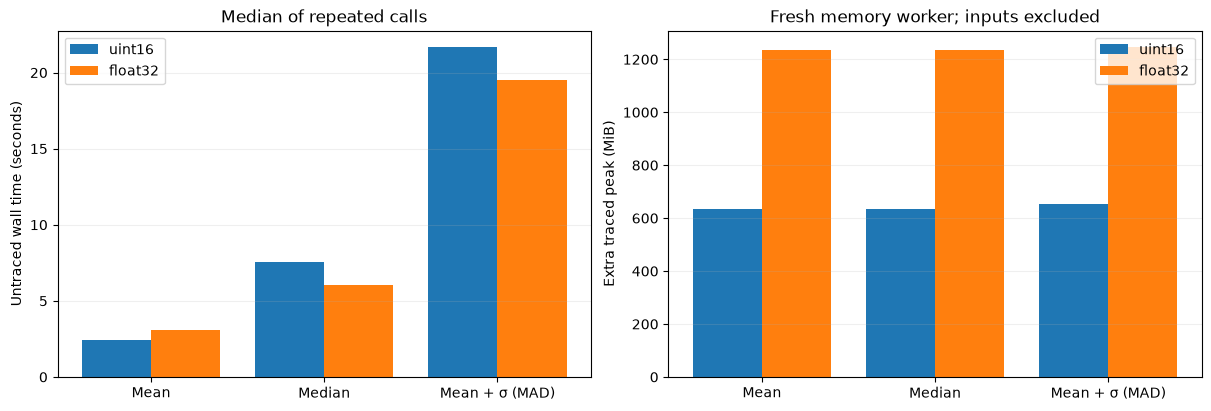

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
x = np.arange(len(benchmark_methods))
for offset, dtype_name in [(-0.2, 'uint16'), (0.2, 'float32')]:
    entries = [benchmarks[name, dtype_name] for name in benchmark_methods]
    axes[0].bar(x+offset, [np.median(m['seconds']) for m in entries], width=0.4, label=dtype_name)
    axes[1].bar(x+offset, [m['traced_peak']/2**20 for m in entries], width=0.4, label=dtype_name)
for ax in axes:
    ax.set_xticks(x, benchmark_methods)
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
axes[0].set(ylabel='Untraced wall time (seconds)', title='Median of repeated calls')
axes[1].set(ylabel='Extra traced peak (MiB)', title='Fresh memory worker; inputs excluded')
plt.show()


## Conclusions

Read the numerical summaries above before choosing an estimator; the observations below distinguish statistical effects from dtype and memory effects.

1. **Raw means include transient contamination.** Their expected center is not the clean analog bias level. The signed-spike mixture predicts an upward shift, partly offset by input quantization. Compare the observed float32 mean and standard deviation with the analytic mixture prediction. Low visual contrast can hide this bias and its tails.
2. **The median resists sparse large spikes, but is less efficient for clean Gaussian noise.** Its asymptotic sampling scatter is about 1.253 times that of the mean at the same frame count. Quantization, the finite sample count, and asymmetric contamination change the precise values. No estimator can recover fractions already discarded when the input frames were cast to uint16.
3. **Half-ADU median values are expected for even frame counts.** They arise from the two central integer samples, and ties make integer outcomes more frequent. The measured central-tie and half-integer percentages quantify this rather than assuming equal frequencies. Integer output discards half-ADU values; float32 retains them.
4. **Clipping can combine robustness with the mean's efficiency.** Compare the clipped means' bias, ordinary scatter, robust scatter and RMSE together. Standard-deviation rejection can be inflated by bright spikes; MAD-based rejection is less sensitive to them. A single pass is not equivalent to iterative clipping, and overly strict thresholds also reject legitimate Gaussian samples. The selected-pixel Astropy reference verifies the exact strategy used here. For this model, the clean quantized baseline is approximately `bias_level - 0.5`, so a clipped result near that level should not be mistaken for a remaining half-ADU algorithmic error.
5. **Storage dtype and calculation dtype are different choices.** Current imcombine lets NumPy promote temporary arithmetic, then casts the final result. This fixes uint16 accumulator overflow for the mean. Uint16 outputs still quantize both data and uncertainties, so use float32 when fractional ADU or small standard errors matter. NumPy's usual range/precision limits still apply.
6. **Reported uncertainties need interpretation.** Mean and median results use accepted sample scatter divided by the square root of accepted count. This does not include the median's efficiency factor, nor does it guarantee that transient residuals have Gaussian one-sigma coverage. A narrow uncertainty image alone does not prove an unbiased master bias.
7. **Compare timing and memory on the same workload.** The benchmark regenerates identical inputs, uses the same package and thread settings, and excludes construction from timing. The timing range shows run-to-run variation. RSS includes inputs/interpreter, while traced peak measures extra allocations; neither should be called the other. Input flags and metadata also cost memory. A smaller pixel dtype saves stack storage, but promoted scratch and reductions still have a cost.
8. **This remains a simplified camera experiment.** There is no correlated read noise, drift of the bias level, amplifier nonlinearity, saturation, persistence, EM multiplication or spatial bias structure. Transient rejection cannot identify a persistent defect common to every frame. Real SPARC4 data require measured channel/mode settings and appropriate masks.

Rerun with both spike rates zero to isolate quantization and Gaussian efficiency; change `n_frames` (including odd counts) to study median quantization; change `sigma_threshold` to see the rejection tradeoff. Rebuild `frame_list` after changing simulation parameters so the plots and benchmark refer to the same dataset.

In [14]:
print('Measured conclusions for this run:')
for name in strategies:
    image = results[name]['float32'].data.astype(float)
    print(f'  {name:18s}: bias={image.mean()-bias_level:+.3f} ADU; sigma={image.std():.3f} ADU')
for name in benchmark_methods:
    integer = benchmarks[name, 'uint16']
    floating = benchmarks[name, 'float32']
    ratio = np.median(floating['seconds'])/np.median(integer['seconds'])
    memory_ratio = floating['traced_peak']/integer['traced_peak']
    print(f'  {name:18s}: float32/uint16 time={ratio:.2f}×; extra traced peak={memory_ratio:.2f}×')
print('Ratios describe this machine and workload, not a universal performance guarantee.')


Measured conclusions for this run:
  Mean              : bias=+1.452 ADU; sigma=3.538 ADU
  Median            : bias=-0.442 ADU; sigma=2.183 ADU
  Mean + σ (std)    : bias=-0.502 ADU; sigma=1.755 ADU
  Mean + σ (MAD)    : bias=-0.497 ADU; sigma=1.764 ADU
  Median + σ (MAD)  : bias=-0.498 ADU; sigma=2.208 ADU
  Mean              : float32/uint16 time=1.26×; extra traced peak=1.95×
  Median            : float32/uint16 time=0.80×; extra traced peak=1.95×
  Mean + σ (MAD)    : float32/uint16 time=0.90×; extra traced peak=1.91×
Ratios describe this machine and workload, not a universal performance guarantee.
